In [1]:
import os
from pathlib import Path

from dotenv import load_dotenv
import mlflow
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import normalize
import umap

/home/abdelaziz/Documents/Arix-Research-Paper-Recommendation-System/.venv/lib64/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Locate the repo from the current directory, so the notebook runs from anywhere.
HERE = Path.cwd()
ROOT = next((p for p in (HERE, *HERE.parents) if (p / "pyproject.toml").exists()), None)
if ROOT is None:
    raise RuntimeError(
        f"Start the notebook inside the repo: no pyproject.toml above {HERE}."
    )
DATA_DIR = ROOT / "data"

In [3]:
load_dotenv(ROOT / ".env")  # shell env wins; .env is optional

MLFLOW_TRACKING_URI = os.getenv("MLFLOW_TRACKING_URI", "http://127.0.0.1:5000")
MLFLOW_EXPERIMENT = os.getenv("MLFLOW_EXPERIMENT", "KMeans-clustering")

mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)
mlflow.set_experiment(MLFLOW_EXPERIMENT)

2026/11/02 18:14:45 INFO mlflow.tracking.fluent: Experiment with name 'KMeans-clustering' does not exist. Creating a new experiment.


<Experiment: artifact_location='mlflow-artifacts:/1', creation_time=1793643285457, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1793643285457, lifecycle_stage='active', name='KMeans-clustering', tags={}, trace_location=None, workspace='default'>

In [4]:
sns.set_style("white")
TAB10_PALETTE = sns.color_palette("tab10")

In [5]:
df = pd.read_csv(DATA_DIR / "arxiv_papers_preprocessed_v2.csv")
X = np.load(DATA_DIR / "arxiv_embeddings_v2.npy")

In [6]:
KMEANS_PARAMS = {"init": "k-means++", "n_init": 20, "random_state": 42}

In [7]:
def fit_kmeans(X, k, **params):
    """Fit one K-Means model and return it with its labels."""
    model = KMeans(n_clusters=k, **{**KMEANS_PARAMS, **params})
    labels = model.fit_predict(X)
    return model, labels


def sweep_k(X, k_range, **params):
    """Score K-Means for every k, keeping the fitted models for reuse."""
    ks = list(k_range)
    inertia_list, silhouette_list, models = [], [], {}
    for k in ks:
        model, labels = fit_kmeans(X, k, **params)
        models[k] = model
        inertia_list.append(model.inertia_)
        silhouette_list.append(silhouette_score(X, labels))
    return ks, inertia_list, silhouette_list, models


def plot_k_sweep(ks, inertia_list, silhouette_list, title):
    """Build the elbow + silhouette figure."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
    ax1.plot(
        ks,
        inertia_list,
        marker="o",
        markersize=4,
        linewidth=1.5,
        alpha=0.7,
        color=TAB10_PALETTE[0],
    )
    ax2.plot(
        ks,
        silhouette_list,
        marker="o",
        markersize=4,
        linewidth=1.5,
        alpha=0.7,
        color=TAB10_PALETTE[1],
    )

    ax1.set(xlabel="k (number of clusters)", ylabel="Inertia")
    ax2.set(xlabel="k (number of clusters)", ylabel="Silhouette score")
    ax1.set_title("Elbow method", loc="left", fontsize=11)
    ax2.set_title("Silhouette", loc="left", fontsize=11)
    for ax in (ax1, ax2):
        ax.set_xticks(ks)
        sns.despine(ax=ax)

    fig.suptitle(f"K-Means model selection: {title}", x=0.01, ha="left", fontsize=13)
    plt.tight_layout(rect=(0, 0, 1, 0.92))
    return fig


def log_sweep(run_name, ks, inertia_list, silhouette_list, metadata, params, fig):
    """Log the sweep, the model params used, and its figure to MLflow."""
    with mlflow.start_run(run_name=run_name):
        mlflow.log_params({"k_min": ks[0], "k_max": ks[-1], **params, **metadata})
        for k, inertia, sil in zip(ks, inertia_list, silhouette_list):
            with mlflow.start_run(run_name=f"k={k}", nested=True):
                mlflow.log_param("n_clusters", k)
                mlflow.log_metric("inertia", inertia)
                mlflow.log_metric("silhouette", sil)
        mlflow.log_figure(fig, "elbow_silhouette.png")


def run(X, run_name, metadata, k_range=range(2, 11), **model_params):
    """Run one sweep. `metadata` is logged only; `model_params` configure KMeans."""
    params = {**KMEANS_PARAMS, **model_params}
    ks, inertia_list, silhouette_list, models = sweep_k(X, k_range, **model_params)
    subtitle = ", ".join(f"{key}={value}" for key, value in params.items())
    fig = plot_k_sweep(ks, inertia_list, silhouette_list, f"{run_name}\n{subtitle}")
    log_sweep(run_name, ks, inertia_list, silhouette_list, metadata, params, fig)
    plt.show()
    return ks, inertia_list, silhouette_list, models

🏃 View run k=2 at: http://127.0.0.1:5000/#/experiments/1/runs/bd2877f26dec4f7f9373b6c01523193b
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run k=3 at: http://127.0.0.1:5000/#/experiments/1/runs/7bb04ead927149bebeec3e02cf138663
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run k=4 at: http://127.0.0.1:5000/#/experiments/1/runs/48666a32f3ce4bc58d5ec49bc9ba8e85
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run k=5 at: http://127.0.0.1:5000/#/experiments/1/runs/68a350824262458393d5b257cc74e17a
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run k=6 at: http://127.0.0.1:5000/#/experiments/1/runs/6f41376ee9c04c2692fd483ce369989e
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run k=7 at: http://127.0.0.1:5000/#/experiments/1/runs/6d5d1c7544e040b2a4709389dbab61ed
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run k=8 at: http://127.0.0.1:5000/#/experiments/1/runs/b2e5f7fc

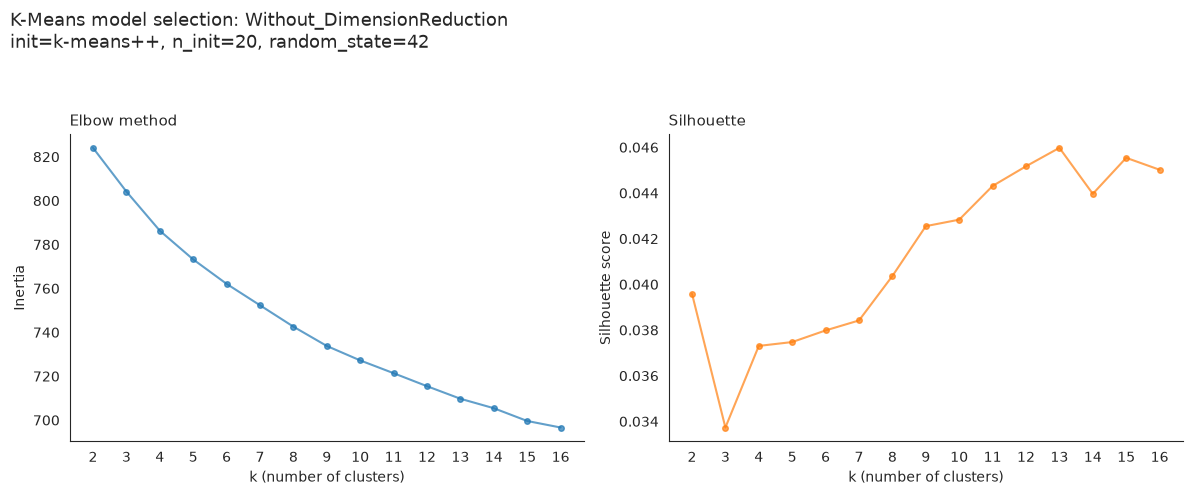

([2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16],
 [824.064208984375,
  804.1357421875,
  786.3060302734375,
  773.211669921875,
  762.075927734375,
  752.3162841796875,
  742.5806884765625,
  733.7771606445312,
  727.1922607421875,
  721.368408203125,
  715.4471435546875,
  709.7210693359375,
  705.4102172851562,
  699.5906982421875,
  696.615234375],
 [0.03958895057439804,
  0.03373183682560921,
  0.037304528057575226,
  0.037473224103450775,
  0.037981919944286346,
  0.03841928765177727,
  0.0403662770986557,
  0.042547691613435745,
  0.04283159598708153,
  0.04430738091468811,
  0.045168790966272354,
  0.045976508408784866,
  0.04396170377731323,
  0.04553915560245514,
  0.04501644894480705],
 {2: KMeans(n_clusters=2, n_init=20, random_state=42),
  3: KMeans(n_clusters=3, n_init=20, random_state=42),
  4: KMeans(n_clusters=4, n_init=20, random_state=42),
  5: KMeans(n_clusters=5, n_init=20, random_state=42),
  6: KMeans(n_clusters=6, n_init=20, random_state=42),
  7: KMeans(n_

In [8]:
run(
    X,
    "Without_DimensionReduction",
    {"preprocessing": "StandardScaler", "reduction": "none"},
    range(2, 17),
)

/home/abdelaziz/Documents/Arix-Research-Paper-Recommendation-System/.venv/lib64/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


🏃 View run k=2 at: http://127.0.0.1:5000/#/experiments/1/runs/027cc8bb1957408992593231c06a42ed
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run k=3 at: http://127.0.0.1:5000/#/experiments/1/runs/35a4a6fdd53b4f4ab33948bc1f2286ba
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run k=4 at: http://127.0.0.1:5000/#/experiments/1/runs/ef5b4b5dc6db4dac9c057daeefe5ad2d
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run k=5 at: http://127.0.0.1:5000/#/experiments/1/runs/fef5a2cd0c4e412192ce4d777611bf7f
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run k=6 at: http://127.0.0.1:5000/#/experiments/1/runs/b0ea1d98412147ea8a37bbe3e1a9b8f3
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run k=7 at: http://127.0.0.1:5000/#/experiments/1/runs/33b1fd137d69481888db10b9f3ea5c7f
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run k=8 at: http://127.0.0.1:5000/#/experiments/1/runs/a812e940

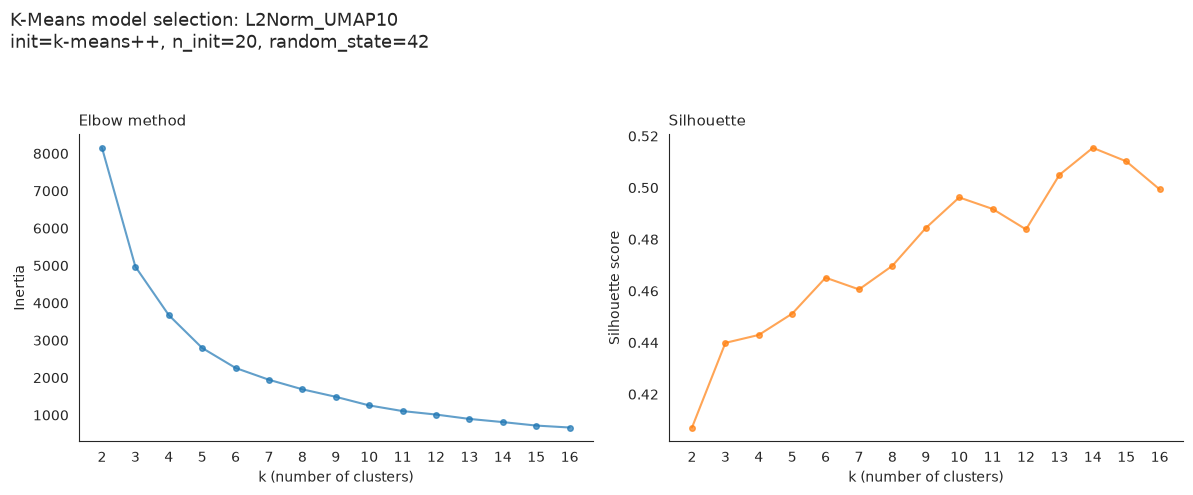

In [9]:
X_norm = normalize(X)
reducer = umap.UMAP(
    n_components=10, n_neighbors=15, min_dist=0.0, metric="cosine", random_state=42
)
X_umap = reducer.fit_transform(X_norm)

ks_umap, inertia_umap, silhouette_umap, models_umap = run(
    X_umap,
    "L2Norm_UMAP10",
    {
        "preprocessing": "L2norm",
        "reduction": "UMAP",
        "umap_n_components": 10,
        "umap_n_neighbors": 15,
        "umap_min_dist": 0.0,
        "umap_metric": "cosine",
    },
    range(2, 17),
)

/home/abdelaziz/Documents/Arix-Research-Paper-Recommendation-System/.venv/lib64/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


🏃 View run kmeans_clusters_umap2d_k6_k9 at: http://127.0.0.1:5000/#/experiments/1/runs/d66538e7c8fb4fd282af268b5c2e4573
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


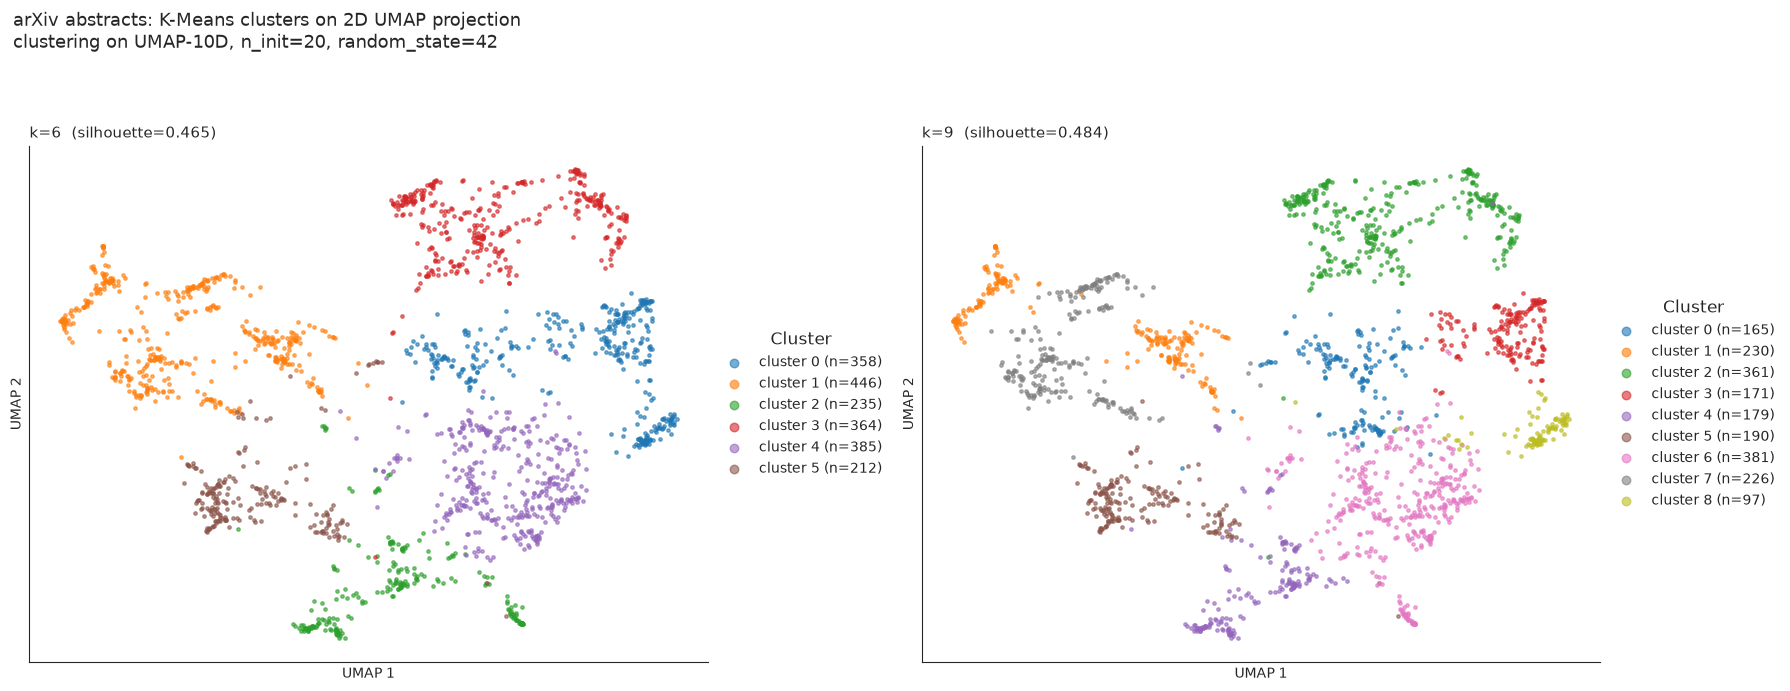

In [10]:
reducer_2d = umap.UMAP(
    n_components=2, n_neighbors=15, min_dist=0.0, metric="cosine", random_state=42
)
X_2d = reducer_2d.fit_transform(X_norm)


candidate_ks = [6, 9]
labels_by_k = {k: models_umap[k].labels_ for k in candidate_ks}
sil_by_k = dict(zip(ks_umap, silhouette_umap))

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

for ax, k in zip(axes, candidate_ks):
    labels = labels_by_k[k]
    colors = TAB10_PALETTE[:k]
    sil = sil_by_k[k]

    for c in range(k):
        mask = labels == c
        ax.scatter(
            X_2d[mask, 0],
            X_2d[mask, 1],
            s=6,
            alpha=0.6,
            color=colors[c],
            label=f"cluster {c} (n={mask.sum()})",
        )

    ax.set_title(f"k={k}  (silhouette={sil:.3f})", loc="left", fontsize=11)
    ax.set_xlabel("UMAP 1")
    ax.set_ylabel("UMAP 2")
    ax.set_xticks([])
    ax.set_yticks([])
    sns.despine(ax=ax)
    ax.legend(
        title="Cluster",
        frameon=False,
        loc="center left",
        bbox_to_anchor=(1.0, 0.5),
        markerscale=2.5,
        fontsize=10,
        title_fontsize=12,
    )

fig.suptitle(
    "arXiv abstracts: K-Means clusters on 2D UMAP projection\n"
    "clustering on UMAP-10D, n_init=20, random_state=42",
    x=0.01,
    ha="left",
    fontsize=13,
)
plt.tight_layout(rect=(0, 0, 1, 0.92))

with mlflow.start_run(run_name="kmeans_clusters_umap2d_k6_k9"):
    mlflow.log_params(
        {
            "candidate_ks": str(candidate_ks),
            "clustering_space": "UMAP10",
            "viz_space": "UMAP2",
            "umap_n_neighbors": 15,
            "umap_min_dist": 0.0,
            "umap_metric": "cosine",
        }
    )
    mlflow.log_figure(fig, "kmeans_umap2d_k6_k9.png")

plt.show()

In [11]:
for k in candidate_ks:
    model = models_umap[k]

    df_out = df.copy()
    df_out["cluster"] = model.labels_
    df_out.to_csv(DATA_DIR / f"data_clustered_k{k}.csv", index=False)

    df_cent = pd.DataFrame(
        model.cluster_centers_,
        columns=[f"umap10_{i}" for i in range(model.cluster_centers_.shape[1])],
    )
    df_cent.insert(0, "cluster", np.arange(k))
    df_cent.to_csv(DATA_DIR / f"centroids_k{k}.csv", index=False)